# Method B: gated beams, ICA, and a family of breathing-rate finders

Method B gives each person a range-gated beam and then lets independent component analysis take apart what the beams could not. It came from recordings where two simulators lay so close in angle that every beam carried both of them. The second part of the method is a set of breathing-rate finders run on sliding windows and fused by their median, because no single finder survived all the clinical conditions.

The scene here is harder than in Method A: two people at the same range, 0° and 5°, far inside one beamwidth.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import beams, cube, simulate, separation, spatial, vitals

people = [simulate.Person(2.0, 0, rr=14, hr=80), simulate.Person(2.0, 5, rr=22, hr=90, amp=0.9)]
x, truth = simulate.simulate(people, duration=90, clutter=[(1.2, 0, 3.0), (2.0, 0, 0.5)], snr_db=20, seed=2)
cfg, fs, t = truth["config"], truth["config"].frame_rate, truth["t"]
rp = cube.compensate_aop(cube.range_fft(x))
pos = cube.aop_positions()
rb = int(round(2.0 / cfg.range_resolution))
true = [1e3 * (d - d.mean()) for d in truth["displacement"]]

## How much a beam leaks

A delay-and-sum beam towards $\theta_1$ passes a second echo from $\theta_2$ with gain $|\mathbf a(\theta_1)^H\mathbf a(\theta_2)|/M$. On the AOP it is close to one at 5° and, because of the sidelobes, still near a third at 25° and 45°:

In [2]:
from radar.spatial import steering
for sep in [5, 10, 15, 25, 45]:
    g = abs(steering(pos, 0.0)[:, 0].conj() @ steering(pos, float(sep))[:, 0]) / len(pos)
    print(f"{sep:3d} deg apart   gain towards the other person {g:.2f}")

  5 deg apart   gain towards the other person 0.96
 10 deg apart   gain towards the other person 0.84
 15 deg apart   gain towards the other person 0.67
 25 deg apart   gain towards the other person 0.32
 45 deg apart   gain towards the other person 0.29


An adaptive beam does not rescue this case either. MVDR can only place a null where the steering vectors differ, and two vectors with a correlation of 0.97 differ very little; the null that removes the second person also removes most of the first.

The leakage is also not what one would expect from a linear mixture. With $z = A_1e^{j\phi_1} + \varepsilon A_2 e^{j\phi_2}$ and small $\varepsilon$,
$$
\angle z \approx \phi_1 + \varepsilon\,\frac{A_2}{A_1}\,\sin(\phi_2-\phi_1),
$$
so the phase of a beam carries a product of the two breathing signals, at sums and differences of their frequencies, not a scaled copy of the neighbour's breathing. Unmixing has to happen before the phase is taken, while the signals still add.

## ICA

Within one range gate the 12 channels are linear mixtures of the people's echoes,
$$
\mathbf x(t) = \mathbf M\,\mathbf s(t) + \mathbf b + \mathbf n(t), \qquad s_j(t) = A_j\,e^{j\phi_j(t)},
$$
where $\mathbf b$ is static and removed with the mean. Each source is a phasor of nearly constant modulus, which is about as far from a Gaussian variable as a complex signal can be, and two people breathe independently. That is what ICA needs. `separation.complex_fastica` whitens the channels and then finds, one by one, unmixing vectors $\mathbf w$ that make $|{\mathbf w^H\mathbf z}|^2$ as non-Gaussian as possible (complex FastICA with $G(u)=\log(a+u)$). It needs no steering vector and no angle grid, which is why it still works below the beamwidth: it separates by rhythm, not by direction. Its limits are the usual ones of ICA: the order and complex scale of the outputs are arbitrary, the mixing must stay constant over the window (nobody turns over), and there cannot be more people than channels.

Method B also has a real-valued variant that runs FastICA on the magnitudes or phases of the gated beams (`separation.ica_beams`). It is cheaper and works on the beams already formed, but the magnitude or phase of a mixture is not a linear mixture of magnitudes or phases, so it separates well only when one person dominates each beam.

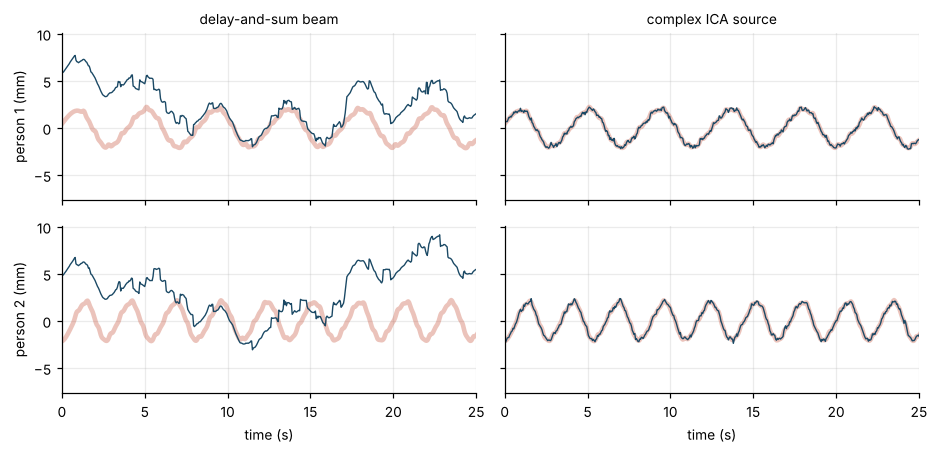

In [3]:
das = beams.beams_for_targets(rp, [(rb, 0.0), (rb, 5.0)], pos, kind="das", gate=1)
chan = rp[..., rb - 1:rb + 2].sum(axis=3).mean(axis=2).T            # (12, frames)
src, unmix = separation.complex_fastica(chan, n=2)

disp = lambda z: 1e3 * vitals.displacement(z, cfg.wavelength, vitals.circle_fit(z)[0])
d_das = np.stack([disp(das[:, k]) for k in range(2)], axis=1)
d_ica = np.stack([disp(s) for s in src], axis=1)
d_ica = separation.match_sources(d_ica, d_das)                      # order by the beams, not by the truth

fig, ax = plt.subplots(2, 2, figsize=(8.6, 4.2), sharex=True, sharey=True)
for k in range(2):
    for j, (d, lab) in enumerate([(d_das, "delay-and-sum beam"), (d_ica, "complex ICA source")]):
        ax[k, j].plot(t, true[k], color="#c8553d", lw=3, alpha=0.35)
        ax[k, j].plot(t, d[:, k] * np.sign(np.corrcoef(d[:, k], true[k])[0, 1]), lw=0.9, color="#1b4965")
        if k == 0:
            ax[k, j].set_title(lab)
    ax[k, 0].set_ylabel(f"person {k + 1} (mm)")
for a in ax[-1]:
    a.set(xlim=(0, 25), xlabel="time (s)")
plt.tight_layout()

The light curves are the true chest motions. The beam towards the second person mostly follows the first one, whose echo is stronger; the ICA sources follow one person each. The sign of a source is arbitrary, so the plot aligns it; nothing else uses the truth.

## A family of breathing-rate finders

The breathing signal of a patient simulator in an asthma attack (33 per minute, shallow) and in bradypnoea (6 per minute, deep) are different problems. Spectral peaks need several cycles inside the window, which 30 s of bradypnoea do not have; peak intervals fail on shallow, noisy breaths; zero crossings count every noise crossing that the band-pass left in; autocorrelation can lock on twice the period. Method B runs four finders on 30 s windows moved by 5 s (`vitals.sliding`) and reports the median of the four per window (`vitals.fused_rate`), which follows the majority and ignores one finder that has gone astray.

Below, one person whose rate drifts from 12 to 22 per minute over two minutes.

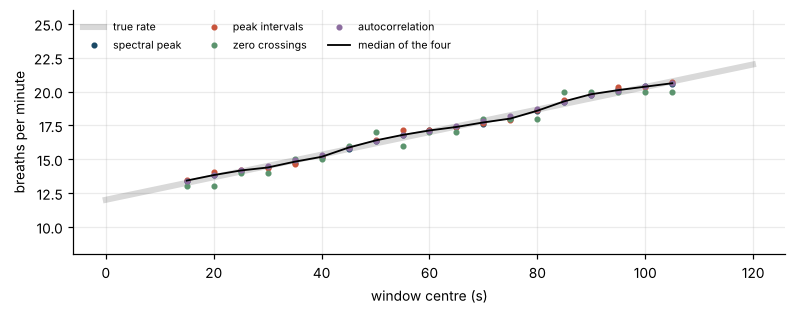

In [4]:
p = simulate.Person(1.8, 0, rr=12, rr_end=22, hr=75)
x2, tr2 = simulate.simulate([p], duration=120, clutter=[(1.4, 0, 3.0)], snr_db=18, seed=5)
rp2 = cube.compensate_aop(cube.range_fft(x2))
z = rp2[:, :, :, int(round(1.8 / cfg.range_resolution))].mean(axis=(1, 2))
resp = vitals.bandpass(vitals.phase(z, vitals.circle_fit(z)[0]), fs, vitals.RR_BAND)

finders = {"spectral peak": (vitals.spectral_rate, {"band": vitals.RR_BAND}),
           "peak intervals": (vitals.peak_count_rate, {"max_rate": 42}),
           "zero crossings": (vitals.zero_crossing_rate, {}),
           "autocorrelation": (vitals.autocorr_rate, {"band": vitals.RR_BAND})}
est = {}
for name, (fn, kw) in finders.items():
    tw, est[name] = vitals.sliding(fn, resp, fs, win_s=30, step_s=5, **kw)
fused = [vitals.fused_rate(r) for r in zip(*est.values())]

fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(tr2["t"], np.linspace(12, 22, len(tr2["t"])), color="k", lw=4, alpha=0.15, label="true rate")
for name, r in est.items():
    ax.plot(tw, r, "o", ms=3, label=name)
ax.plot(tw, fused, color="k", lw=1.2, label="median of the four")
ax.set(xlabel="window centre (s)", ylabel="breaths per minute", ylim=(8, 26))
ax.legend(fontsize=7, ncol=3, loc="upper left")
plt.tight_layout()

Each window reports the average rate over its 30 s, so a change faster than the window is smoothed out, and the spectral finder sees its peak broadened by the drift inside the window. Zero crossings scatter by about one breath per minute because a window holds a whole number of crossings. Shorter windows follow faster changes and lose precision, the trade-off that Method C handles with a spectrogram ridge.